# No-intercept matched logistic/logistic: solver sensitivity

Exploratory, outcome-guided sensitivity analysis, not independently validated
model selection. All fits use **logistic loss, zero intercept, zero explicit
penalty**, and zero coefficient starts. The same fit (solver, budget, step and
random seed) is used in the auxiliary and posterior stages. The count prior
remains 1/2 for each count; location given one change is uniform on admissible
distinct-age splits. Data preprocessing and the audited joint likelihood are
unchanged. No likelihood temperature or count-prior tuning is used.

45 fitting configurations: FISTA/GD budgets 1,3,8,16,30 at step multipliers .1,1;
L-BFGS budgets 1,2,3,5,8,12,20; SGD epochs 1,3,10 at step multipliers .1,1 and
seeds 42,123; SAGA epochs 1,3,10 and seeds 42,123. Solver iterations and stochastic
epochs are different computational units. FISTA/GD steps use global weighted
curvature; SGD uses a maximum weighted per-observation curvature bound.
Weights are normalized explicitly; no hidden penalty or intercept is fitted.
Liblinear is excluded: it does not support a genuinely unpenalized objective.

Delta=1,5,10; rho starts at identity, with damping .25 and eigenvalues clipped to
[1e-4,100]. Save rho updates 1,3,6,10,20,30: **810 matched comparisons**, run on
36 jobs. Primary state solves use 256 QMC points, seed42, budget60. Selected
shape leaders overall/by solver, and shape leaders with .5<=P(1)<.99, are
rechecked with 512/1024 QMC points and seeds42/123, budget100. Likelihood
quadrature order160. The explicit .99 cutoff is a reporting preference, not a
theoretical calibration guarantee. Nothing forces such a candidate to exist.

Report the ten closest conditional shapes and, separately, up to ten meeting
the nonextreme probability preference in **both** numerical checks. All primary
results, failures, residuals and checkpoints are retained. Finite-fit state
equations remain heuristic, numerical ranges are not confidence intervals,
and a probability rounding to 1 is not necessarily exact certainty: P(0) and
log-odds are saved too. Original reference curves are not edited.


In [1]:
"""Matched unpenalized solver sensitivity, with an unchanged posterior model."""
from tools.myocardial_finite_iteration_exploration import *
from WERM.myocardial_no_intercept_solvers import fit_column

SWEEP_DELTAS = (1, 5, 10)
RHO_UPDATES = (1, 3, 6, 10, 20, 30)


def configurations():
    grid = []
    for method in ('fista', 'gd'):
        grid += [(method, b, s, 42) for b in (1, 3, 8, 16, 30) for s in (.1, 1.)]
    grid += [('lbfgs', b, 1., 42) for b in (1, 2, 3, 5, 8, 12, 20)]
    grid += [('sgd', b, s, seed) for b in (1, 3, 10) for s in (.1, 1.) for seed in (42, 123)]
    grid += [('saga', b, 1., seed) for b in (1, 3, 10) for seed in (42, 123)]
    return grid


def fit_name(config):
    method, budget, scale, seed = config
    return f'{method}_b{budget}_step{scale:g}_seed{seed}'


def setting_for(d, y, locations):
    eta, prior, phi = configuration_prior(len(y), locations[(locations >= d)&(locations <= len(y)-d)])
    return dict(delta_min=d, eta=eta, prior=prior, phi=phi, fits={})


def prepare_case(d, config, X, y, locations, root):
    name = fit_name(config); path = root/f'aux_d{d}_{name}.pkl'
    if path.exists(): return pickle.load(path.open('rb'))
    try:
        setting = setting_for(d, y, locations)
        columns = [fit_column(X, y, w, *config) for w in setting['phi']]
        B = np.column_stack([c['coef'] for c in columns]); theta = X@B
        V, b = empirical_adjustment(theta, y, setting['phi'], len(y)/X.shape[1], loss='logistic')
        if not np.isfinite(V).all(): raise FloatingPointError('nonfinite adjustment')
        fit = dict(theta=theta, V=V, b=b, coef=B, budget=config[1],
                   checks=columns, penalty='none', strength=0.)
        e, psi = pilot(theta, y, setting['eta'], 'logistic')
        S = V.T@V/len(y); rho = np.eye(2); scenarios = []
        import WERM.myocardial_approximate as impl
        old = impl.logistic_prox; impl.logistic_prox = logistic_prox_fast
        try:
            for it in range(1, max(RHO_UPDATES)+1):
                state = impl.logistic_state(rho, setting['phi'], psi, len(y)/X.shape[1], sample_power=7, max_nfev=30)
                inv = np.linalg.pinv(state['lambda'], rcond=1e-6)
                rho = project_covariance(.75*rho+.25*project_covariance(inv.T@(S-state['kappa'])@inv))
                if it in RHO_UPDATES:
                    check = impl.logistic_state(rho, setting['phi'], psi, len(y)/X.shape[1], sample_power=8, max_nfev=60)
                    scenarios.append(dict(rho=rho.copy(), iteration=it, auxiliary=name,
                        auxiliary_budget=config[1], pilot=e, loss='logistic',
                        moment_residual=float(np.linalg.norm(check['lambda'].T@rho@check['lambda']+check['kappa']-S)),
                        state_residual=check['training_residual']))
        finally: impl.logistic_prox = old
        result = dict(setting=setting, fit=fit, scenarios=scenarios, config=config)
    except Exception:
        result = dict(error=traceback.format_exc(), delta=d, config=config)
    atomic_save(path, result)
    print('Auxiliary ready:', d, name, 'error' if 'error' in result else 'ok', flush=True)
    return result


def evaluate_case(prepared, scenario, X, y, ages, reference, root, power=8, seed=42, budget=60):
    setting = prepared['setting']; name = scenario['auxiliary']
    case = f"d{setting['delta_min']}_{name}_rho{scenario['iteration']}"
    tag = f'q{power}_seed{seed}_b{budget}'
    path = root/f'{case}_{tag}_score.pkl'
    if path.exists(): return pickle.load(path.open('rb'))
    partial = root/f'{case}_{tag}_partial.pkl'
    states = pickle.load(partial.open('rb')) if partial.exists() else []
    import WERM.myocardial_approximate as impl
    old = impl.logistic_prox; impl.logistic_prox = logistic_prox_fast
    try:
        for e in setting['eta'][len(states):]:
            psi = np.zeros(len(y), int) if e < 0 else (np.arange(len(y)) >= e).astype(int)
            states.append(impl.logistic_state(scenario['rho'], setting['phi'], psi,
                len(y)/X.shape[1], sample_power=power, max_nfev=budget, seed=seed))
            if len(states)%8 == 0: atomic_save(partial, states)
        atomic_save(partial, states)
        rec = dict(label=case, scenario=scenario)
        row = score_fit(rec, states, setting, name, prepared['fit'], X, y, ages, reference, root, tag)
        row.update(solver=prepared['config'][0], step_scale=prepared['config'][2],
            fit_seed=prepared['config'][3], intercept=False, penalty='none',
            checkpoint=str(path), pilot_index=scenario['pilot'])
        # Stable log-odds/P(0) diagnostics distinguish rounding to 1 from exact certainty.
        logmass = row['log_likelihood'] + np.log(setting['prior'])
        row['log_odds_1_vs_0'] = float(logsumexp(logmass[1:])-logmass[0])
        row['P_0'] = float(expit(-row['log_odds_1_vs_0']))
    except Exception:
        row = dict(error=traceback.format_exc(), case=case, tag=tag)
    finally: impl.logistic_prox = old
    atomic_save(path, row)
    return row


def table(rows):
    return pd.DataFrame([{k:v for k,v in r.items() if k not in ('conditional','ages','log_likelihood')} for r in rows if 'error' not in r])


def select_checks(frame):
    groups = [frame] + [g for _,g in frame.groupby('solver')]
    selected = []
    for group in groups:
        selected.append(group.nsmallest(3, 'TV_to_reference'))
        middle = group[group.P_1.between(.5, .99, inclusive='left')]
        selected.append(middle.nsmallest(3, 'TV_to_reference'))
    return pd.concat(selected).drop_duplicates('case')


def run(smoke=False):
    X,y,ages,locations = load_data(); reference = reference_distribution()
    spec = dict(configurations=configurations(), deltas=SWEEP_DELTAS, rho_updates=RHO_UPDATES,
        rho_start='identity', damping=.25, eigenvalue_bounds=[1e-4,100], intercept=False,
        penalty='none', match='same solver, budget, step and random seed in both stages; same fit reused',
        count_prior=[.5,.5], conditional_prior='uniform admissible distinct-age splits',
        primary=[8,42,60], validation=[[9,42,100],[10,123,100]],
        selection='shape leaders overall and by solver; also 0.5 <= P1 < 0.99 shape leaders; post hoc',
        files={p:hashlib.sha256(Path(p).read_bytes()).hexdigest() for p in
            ('tools/myocardial_no_intercept_sweep.py','WERM/myocardial_no_intercept_solvers.py',
             'WERM/myocardial_approximate.py','WERM/signal_strength.py')})
    digest = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:12]
    root = Path('results')/('myocardial_no_intercept_solvers_'+digest); root.mkdir(exist_ok=True)
    (root/'specification.json').write_text(json.dumps(spec, indent=2))
    if smoke:
        setting = setting_for(1,y,locations)
        for method in ('fista','gd','lbfgs','sgd','saga'):
            cols = [fit_column(X,y,w,method,3) for w in setting['phi']]
            theta=X@np.column_stack([c['coef'] for c in cols])
            V,b=empirical_adjustment(theta,y,setting['phi'],len(y)/X.shape[1],loss='logistic')
            assert np.isfinite(V).all()
        tiny=dict(setting,eta=setting['eta'][:2],prior=np.array([.5,.5]))
        prepared=dict(setting=tiny,fit=dict(theta=theta,V=V,b=b,budget=3,checks=cols),config=('saga',3,1.,42))
        scenario=dict(rho=np.eye(2),iteration=1,auxiliary='smoke',auxiliary_budget=3,moment_residual=0.,pilot=-1)
        checked=evaluate_case(prepared,scenario,X,y,ages,reference,root,5,42,3)
        assert 'error' not in checked, checked
        assert np.isfinite(checked['log_odds_1_vs_0'])
        print('All five real-data fit adapters and two-location posterior smoke passed.',flush=True)
        return root
    print('Starting',len(configurations())*len(SWEEP_DELTAS)*len(RHO_UPDATES),'matched comparisons:',root,flush=True)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        prepared=Parallel(n_jobs=36)(delayed(prepare_case)(d,c,X,y,locations,root) for d in SWEEP_DELTAS for c in configurations())
        errors=[r for r in prepared if 'error' in r]
        jobs=[(p,s) for p in prepared if 'error' not in p for s in p['scenarios']]
        rows=Parallel(n_jobs=36)(delayed(evaluate_case)(p,s,X,y,ages,reference,root) for p,s in jobs)
        errors += [r for r in rows if 'error' in r]
        summary=table(rows); summary.to_csv(root/'summary.csv',index=False)
        if summary.empty: raise RuntimeError('No successful primary results; inspect checkpoints')
        selected=select_checks(summary); selected.to_csv(root/'selected_for_validation.csv',index=False)
        wanted=set(selected.case)
        follow=[(p,s) for p,s in jobs if f"d{p['setting']['delta_min']}_{s['auxiliary']}_rho{s['iteration']}" in wanted]
        checked=Parallel(n_jobs=36)(delayed(evaluate_case)(p,s,X,y,ages,reference,root,power,seed,100)
            for p,s in follow for power,seed in ((9,42),(10,123)))
    errors += [r for r in checked if 'error' in r]
    (root/'errors.json').write_text(json.dumps(errors,indent=2,default=str))
    validation=table(checked); validation.to_csv(root/'validation.csv',index=False)
    ranked=validation.groupby('case',as_index=False).agg(
        checks=('P_1','size'), solver=('solver','first'),fit_budget=('posterior_budget','first'),
        step_scale=('step_scale','first'),fit_seed=('fit_seed','first'),Delta=('Delta','first'),
        rho_updates=('rho_updates','first'),P1_min=('P_1','min'),P1_max=('P_1','max'),
        mean_TV=('TV_to_reference','mean'),max_TV=('TV_to_reference','max'),
        peak_min=('peak_age','min'),peak_max=('peak_age','max'),
        mass_above55_min=('mass_above55','min'),moment_residual=('moment_residual','max'),
        FP_residual_max=('FP_residual_max','max'))
    ranked=ranked[ranked.checks==2].sort_values('mean_TV')
    ranked.to_csv(root/'ranked.csv',index=False)
    ranked.head(10).to_csv(root/'top_ten_shape.csv',index=False)
    ranked[(ranked.P1_min>=.5)&(ranked.P1_max<.99)].head(10).to_csv(root/'top_ten_nonextreme.csv',index=False)
    print('NO-INTERCEPT SWEEP COMPLETE; errors:',len(errors),flush=True)
    return root




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
root = run()
print("Results:", root)

Starting 810 matched comparisons: results/myocardial_no_intercept_solvers_57efc84323e8


Auxiliary ready: 1 sgd_b3_step0.1_seed123 ok


Auxiliary ready: 1 gd_b3_step0.1_seed42 ok
Auxiliary ready: 1 sgd_b1_step1_seed42 ok


Auxiliary ready: 1 fista_b16_step0.1_seed42 ok


Auxiliary ready: 1 gd_b8_step1_seed42 ok


Auxiliary ready: 1 lbfgs_b1_step1_seed42 ok


... (90 outputs left out)

Auxiliary ready: 10 lbfgs_b8_step1_seed42 ok


Auxiliary ready: 10 lbfgs_b12_step1_seed42 ok


NO-INTERCEPT SWEEP COMPLETE; errors: 0


Results: results/myocardial_no_intercept_solvers_57efc84323e8


In [3]:
from IPython.display import display
ranked = pd.read_csv(root/'ranked.csv')
shape = pd.read_csv(root/'top_ten_shape.csv')
preferred = pd.read_csv(root/'top_ten_nonextreme.csv')
print('Ten closest shapes, regardless of probability:')
display(shape)
print('Closest shapes with 0.5 <= P(1) < 0.99 in both numerical checks:')
display(preferred)
print('Failures (retained):', len(json.loads((root/'errors.json').read_text())))


Ten closest shapes, regardless of probability:


,case,checks,solver,fit_budget,step_scale,fit_seed,Delta,rho_updates,P1_min,P1_max,mean_TV,max_TV,peak_min,peak_max,mass_above55_min,moment_residual,FP_residual_max
0,d1_saga_b1_step1_seed42_rho30,2,saga,1,1.0,42,1,30,0.501481,0.507032,0.642507,0.644897,69.0,69.0,0.583497,0.105473,1.188796e-09
1,d1_sgd_b1_step1_seed123_rho30,2,sgd,1,1.0,123,1,30,0.509899,0.523350,0.646224,0.651890,68.0,69.0,0.600701,0.339130,1.188796e-09
2,d1_sgd_b10_step0.1_seed123_rho30,2,sgd,10,0.1,123,1,30,0.512685,0.526861,0.648933,0.654864,67.0,68.0,0.601232,0.387354,1.188796e-09
3,d1_sgd_b10_step0.1_seed42_rho30,2,sgd,10,0.1,42,1,30,0.512686,0.526859,0.648966,0.654897,67.0,68.0,0.601139,0.387646,1.188796e-09
4,d1_gd_b8_step0.1_seed42_rho30,2,gd,8,0.1,42,1,30,0.513756,0.529779,0.651176,0.657884,66.0,68.0,0.598523,0.453731,1.188796e-09
5,d1_fista_b3_step0.1_seed42_rho30,2,fista,3,0.1,42,1,30,0.515978,0.535609,0.656174,0.664357,65.0,66.0,0.591193,0.588539,1.188796e-09
6,d1_gd_b3_step0.1_seed42_rho30,2,gd,3,0.1,42,1,30,0.516086,0.535869,0.656418,0.664662,65.0,66.0,0.590774,0.594359,1.188796e-09
7,d1_lbfgs_b1_step1_seed42_rho30,2,lbfgs,1,1.0,42,1,30,0.516530,0.536336,0.657566,0.665803,64.0,66.0,0.588579,0.603840,1.188796e-09
8,d1_gd_b1_step0.1_seed42_rho30,2,gd,1,0.1,42,1,30,0.516670,0.537006,0.657571,0.666029,64.0,66.0,0.588605,0.616668,1.188796e-09
9,d1_fista_b1_step0.1_seed42_rho30,2,fista,1,0.1,42,1,30,0.516670,0.537006,0.657571,0.666029,64.0,66.0,0.588605,0.616668,1.188796e-09


Closest shapes with 0.5 <= P(1) < 0.99 in both numerical checks:


,case,checks,solver,fit_budget,step_scale,fit_seed,Delta,rho_updates,P1_min,P1_max,mean_TV,max_TV,peak_min,peak_max,mass_above55_min,moment_residual,FP_residual_max
0,d1_saga_b1_step1_seed42_rho30,2,saga,1,1.0,42,1,30,0.501481,0.507032,0.642507,0.644897,69.0,69.0,0.583497,0.105473,1.188796e-09
1,d1_sgd_b1_step1_seed123_rho30,2,sgd,1,1.0,123,1,30,0.509899,0.523350,0.646224,0.651890,68.0,69.0,0.600701,0.339130,1.188796e-09
2,d1_sgd_b10_step0.1_seed123_rho30,2,sgd,10,0.1,123,1,30,0.512685,0.526861,0.648933,0.654864,67.0,68.0,0.601232,0.387354,1.188796e-09
3,d1_sgd_b10_step0.1_seed42_rho30,2,sgd,10,0.1,42,1,30,0.512686,0.526859,0.648966,0.654897,67.0,68.0,0.601139,0.387646,1.188796e-09
4,d1_gd_b8_step0.1_seed42_rho30,2,gd,8,0.1,42,1,30,0.513756,0.529779,0.651176,0.657884,66.0,68.0,0.598523,0.453731,1.188796e-09
5,d1_fista_b3_step0.1_seed42_rho30,2,fista,3,0.1,42,1,30,0.515978,0.535609,0.656174,0.664357,65.0,66.0,0.591193,0.588539,1.188796e-09
6,d1_gd_b3_step0.1_seed42_rho30,2,gd,3,0.1,42,1,30,0.516086,0.535869,0.656418,0.664662,65.0,66.0,0.590774,0.594359,1.188796e-09
7,d1_lbfgs_b1_step1_seed42_rho30,2,lbfgs,1,1.0,42,1,30,0.516530,0.536336,0.657566,0.665803,64.0,66.0,0.588579,0.603840,1.188796e-09
8,d1_gd_b1_step0.1_seed42_rho30,2,gd,1,0.1,42,1,30,0.516670,0.537006,0.657571,0.666029,64.0,66.0,0.588605,0.616668,1.188796e-09
9,d1_fista_b1_step0.1_seed42_rho30,2,fista,1,0.1,42,1,30,0.516670,0.537006,0.657571,0.666029,64.0,66.0,0.588605,0.616668,1.188796e-09


Failures (retained): 0


Top ten by conditional shape


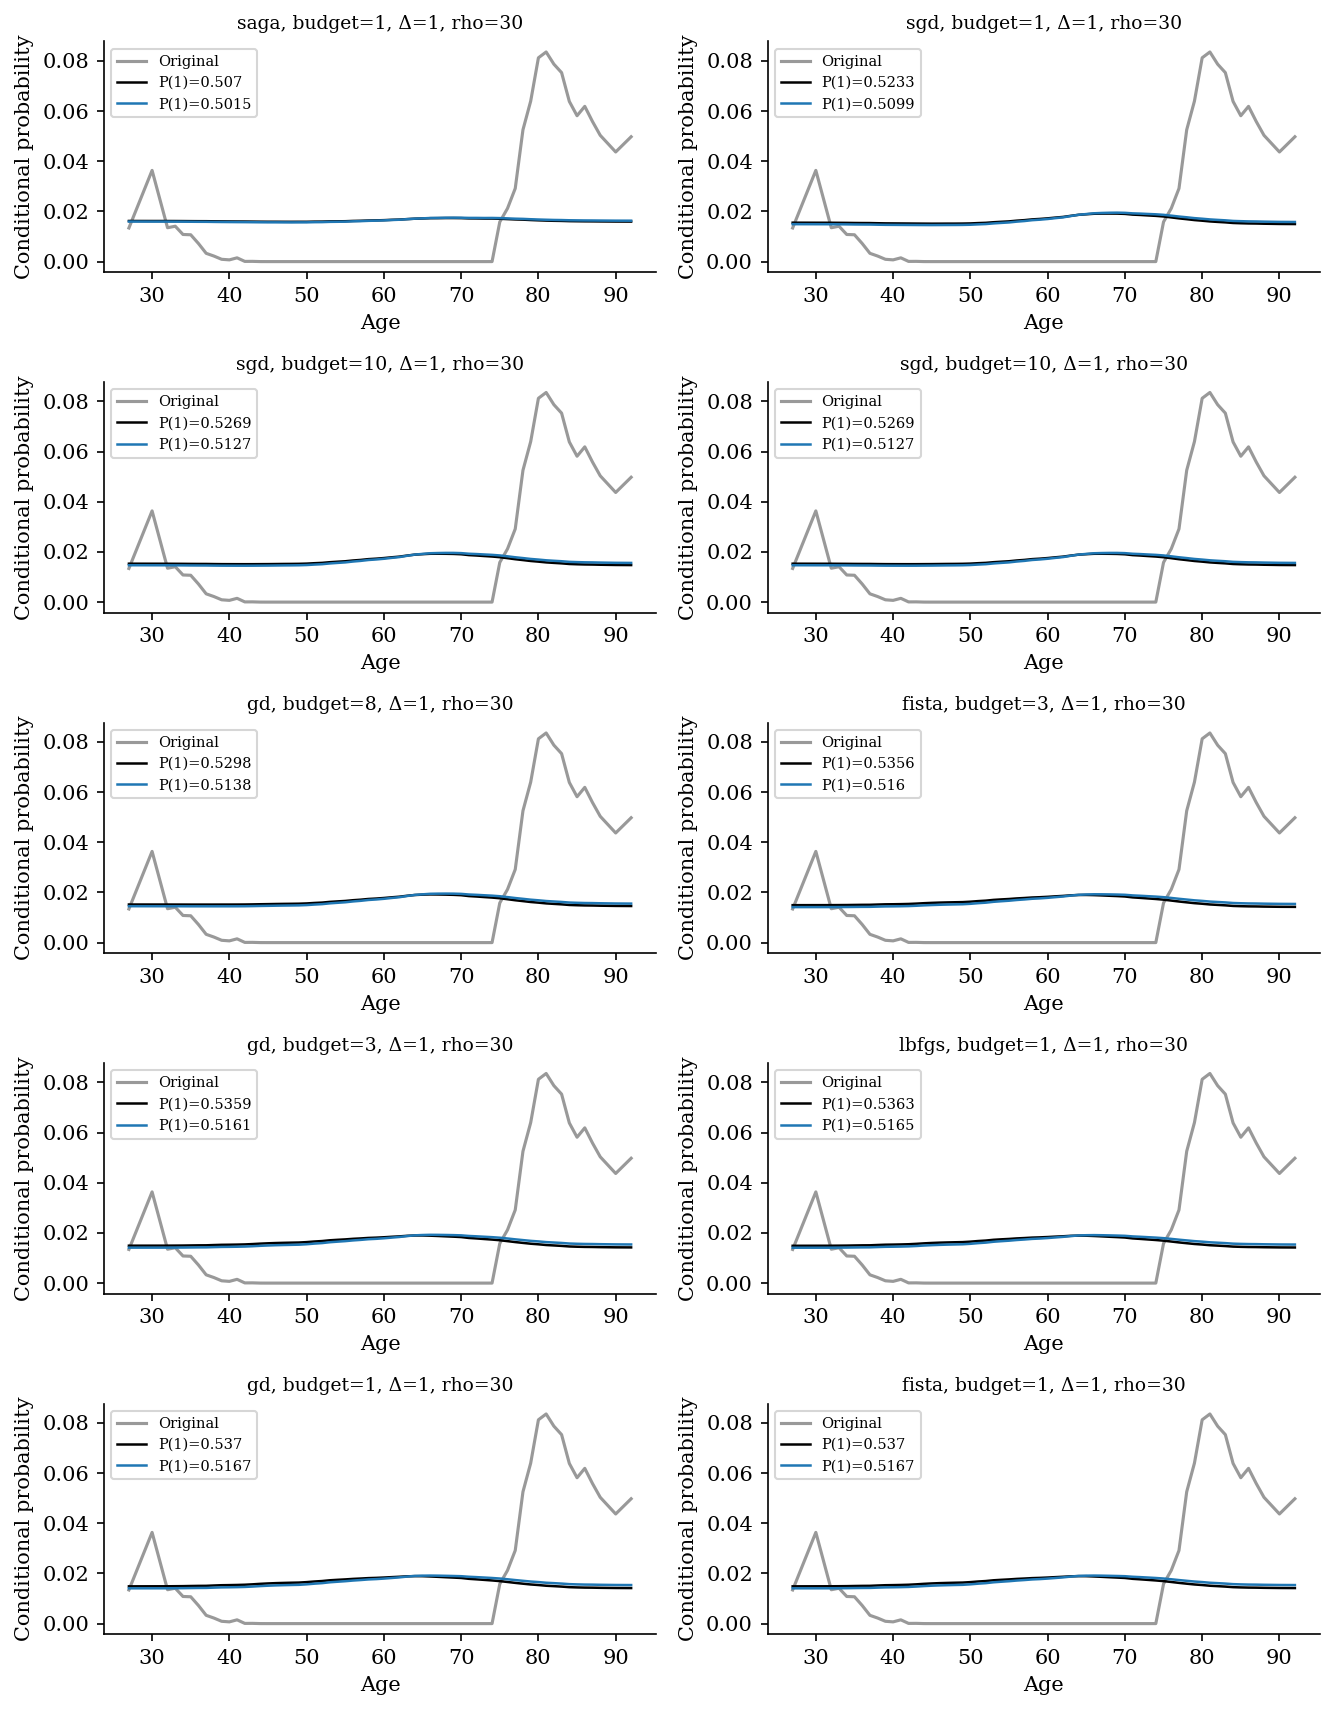

Top nonextreme-probability candidates


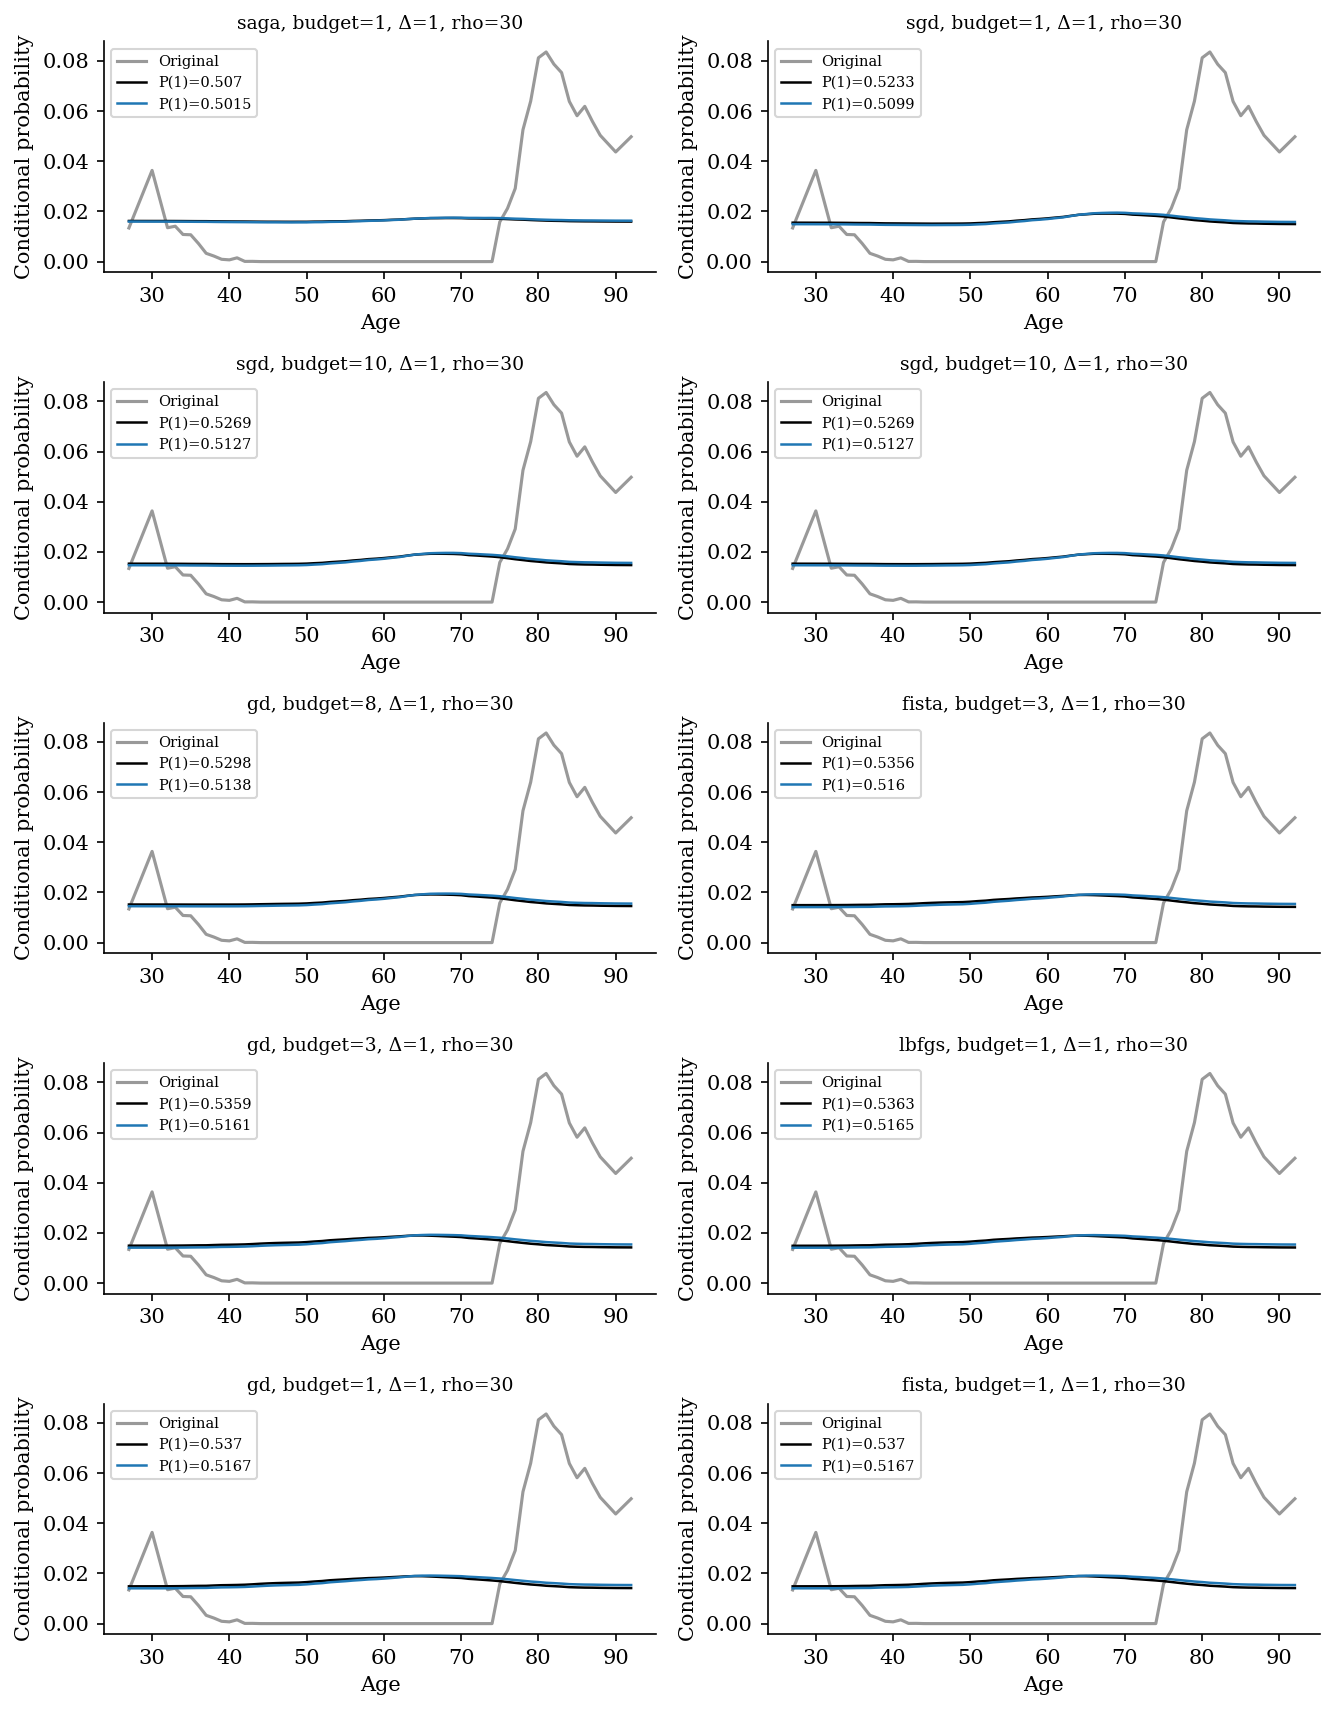

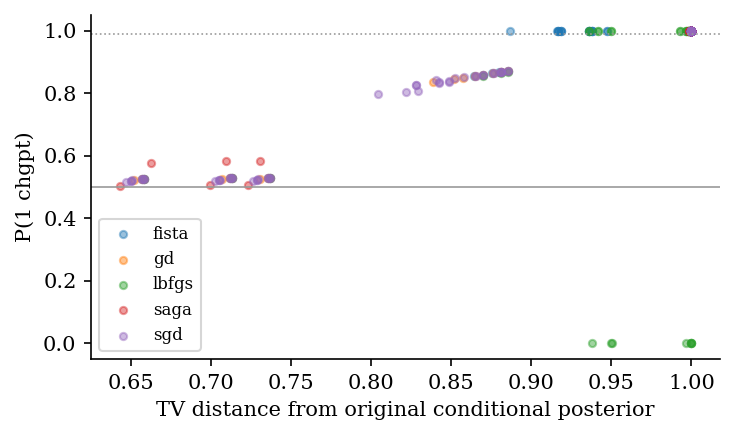

In [4]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':10,
                     'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
reference = reference_distribution()
ref_ages=np.array(sorted(reference)); ref_prob=np.array([reference[a] for a in ref_ages])
validation=pd.read_csv(root/'validation.csv')
def plot_group(frame, heading):
    print(heading)
    if frame.empty:
        print('No candidate satisfies this reporting criterion; no favorable result is substituted.')
        return
    fig, axes=plt.subplots(int(np.ceil(len(frame)/2)),2,figsize=(9,2.3*int(np.ceil(len(frame)/2))),squeeze=False)
    for ax,row in zip(axes.flat,frame.itertuples()):
        ax.plot(ref_ages,ref_prob,color='.6',label='Original')
        records=validation[validation.case==row.case].sort_values('tag')
        for color,entry in zip(('black','tab:blue'),records.itertuples()):
            rec=pickle.load(open(entry.checkpoint,'rb'))
            ax.plot(rec['ages'],rec['conditional'],color=color,linewidth=1.2,
                    label=f"P(1)={rec['P_1']:.4g}")
        ax.set_title(f'{row.solver}, budget={row.fit_budget}, Δ={row.Delta}, rho={row.rho_updates}',fontsize=9)
        ax.set_xlabel('Age');ax.set_ylabel('Conditional probability');ax.legend(fontsize=7)
    for ax in list(axes.flat)[len(frame):]:ax.set_visible(False)
    fig.tight_layout();plt.show()
plot_group(shape,'Top ten by conditional shape')
plot_group(preferred,'Top nonextreme-probability candidates')
primary=pd.read_csv(root/'summary.csv')
fig,ax=plt.subplots(figsize=(5,3))
for solver,g in primary.groupby('solver'):
    ax.scatter(g.TV_to_reference,g.P_1,s=12,alpha=.45,label=solver)
ax.axhline(.5,color='.6',linewidth=.8);ax.axhline(.99,color='.6',linewidth=.8,linestyle=':')
ax.set(xlabel='TV distance from original conditional posterior',ylabel='P(1 chgpt)')
ax.legend(fontsize=8);fig.tight_layout();plt.show()


## Interpretation
These rankings describe sensitivity to implicit regularization, not evidence for
choosing optimization settings because they produce a desired scientific answer.
Check moment/state residuals, seed sensitivity and neighboring settings before
using a curve. A sharp or diffuse posterior is reported even if undesirable.
The separate intercept-enabled study retains its own top-ten notebook.
